In [3]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [5]:
class CNN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """CNN para extrair padrões locais + GRU para dependências temporais"""

    def __init__(self,
                 cnn_filters=[16, 32],
                 cnn_kernels=[3, 3],
                 cnn_dropout=0.2,
                 gru_hidden=32,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(16,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.cnn_filters = cnn_filters
        self.cnn_kernels = cnn_kernels
        self.cnn_dropout = cnn_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class CNN_GRU_Model(nn.Module):
            def __init__(self, input_size, cnn_filters, cnn_kernels, cnn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(CNN_GRU_Model, self).__init__()

                # CNN Layers
                conv_layers = []
                prev_channels = 1

                for filters, kernel in zip(cnn_filters, cnn_kernels):
                    conv_layers.append(
                        nn.Conv1d(prev_channels, filters, kernel, padding='same')
                    )
                    conv_layers.append(nn.BatchNorm1d(filters))
                    conv_layers.append(nn.ReLU())
                    conv_layers.append(nn.MaxPool1d(2))
                    conv_layers.append(nn.Dropout(cnn_dropout))
                    prev_channels = filters

                self.conv_layers = nn.Sequential(*conv_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_channels,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(cnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # CNN
                x = x.unsqueeze(1)  # (batch, 1, features)
                x = self.conv_layers(x)  # (batch, channels, features_cnn)

                # Reshape para GRU
                x = x.permute(0, 2, 1)  # (batch, features_cnn, channels)

                # GRU
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                # Dropout e FC
                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return CNN_GRU_Model(
            input_size=self.input_size,
            cnn_filters=self.cnn_filters,
            cnn_kernels=self.cnn_kernels,
            cnn_dropout=self.cnn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
               # print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'cnn_filters': self.cnn_filters,
            'cnn_kernels': self.cnn_kernels,
            'cnn_dropout': self.cnn_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_606/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.9992
Precision: 0.9992
Recall: 0.9992
F1: 0.9992
Kappa: 0.9990
Error Rate: 0.0008

TEST
Accuracy: 0.1549
Precision: 0.1207
Recall: 0.1549
F1: 0.1241
Kappa: 0.0114
Error Rate: 0.8451
Gap (overfitting): 0.8443

CV
Mean: 0.8196
Std: 0.1621
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



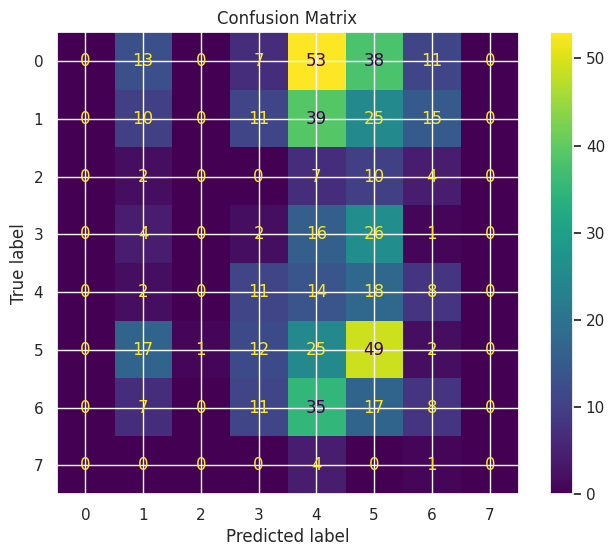

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_GRU_adam
------------------------------
TRAIN
Accuracy: 0.9343
Precision: 0.9348
Recall: 0.9343
F1: 0.9345
Kappa: 0.9208
Error Rate: 0.0657

TEST
Accuracy: 0.1269
Precision: 0.1351
Recall: 0.1269
F1: 0.0914
Kappa: -0.0126
Error Rate: 0.8731
Gap (overfitting): 0.8075

CV
Mean: 0.8342
Std: 0.1734
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



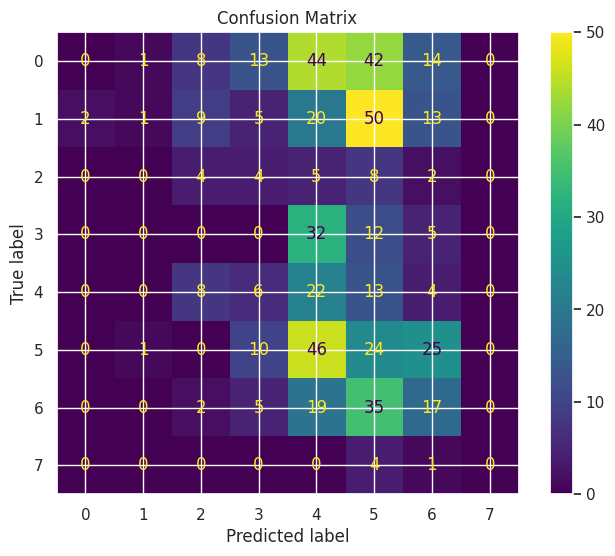

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_GRU_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.7582
Precision: 0.7769
Recall: 0.7582
F1: 0.7501
Kappa: 0.7051
Error Rate: 0.2418

TEST
Accuracy: 0.1884
Precision: 0.1600
Recall: 0.1884
F1: 0.1383
Kappa: 0.0742
Error Rate: 0.8116
Gap (overfitting): 0.5698

CV
Mean: 0.7277
Std: 0.1035
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



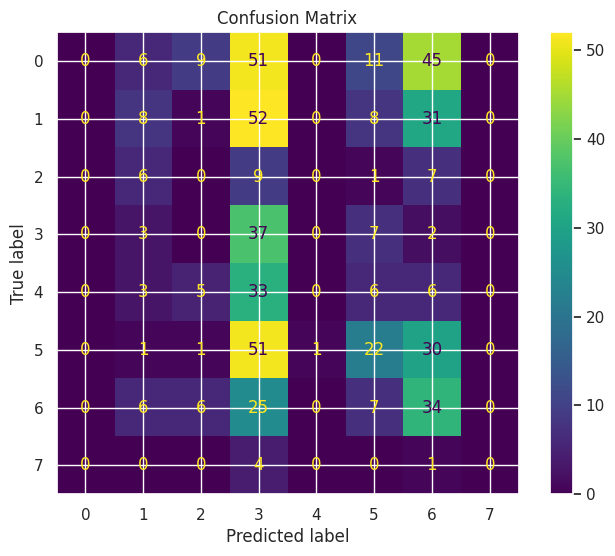

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_GRU_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.5292
Precision: 0.5430
Recall: 0.5292
F1: 0.5066
Kappa: 0.4197
Error Rate: 0.4708

TEST
Accuracy: 0.1772
Precision: 0.1483
Recall: 0.1772
F1: 0.1053
Kappa: 0.0296
Error Rate: 0.8228
Gap (overfitting): 0.3520

CV
Mean: 0.6168
Std: 0.0756
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



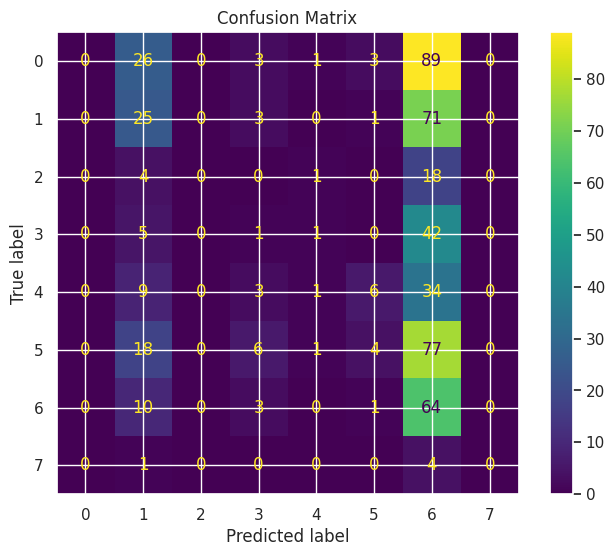

In [6]:
models_cnn_gru = {}

models_cnn_gru['CNN_GRU_rmsprop'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn_gru['CNN_GRU_adam'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn_gru['CNN_GRU_sgd_momentum'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_gru['CNN_GRU_adam_lowLR'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_cnn_gru, "cnn_gru_experiments")

/tmp/ipykernel_606/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_1
------------------------------
TRAIN
Accuracy: 0.7990
Precision: 0.7843
Recall: 0.7990
F1: 0.7863
Kappa: 0.7560
Error Rate: 0.2010

TEST
Accuracy: 0.0634
Precision: 0.2330
Recall: 0.0634
F1: 0.0316
Kappa: -0.0395
Error Rate: 0.9366
Gap (overfitting): 0.7356

CV
Mean: 0.8286
Std: 0.0811
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



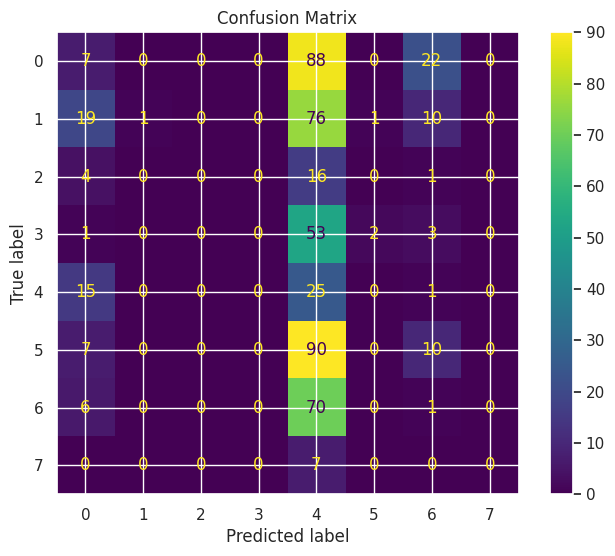

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_2
------------------------------
TRAIN
Accuracy: 0.9095
Precision: 0.9141
Recall: 0.9095
F1: 0.9066
Kappa: 0.8905
Error Rate: 0.0905

TEST
Accuracy: 0.2164
Precision: 0.1989
Recall: 0.2164
F1: 0.1424
Kappa: 0.0444
Error Rate: 0.7836
Gap (overfitting): 0.6931

CV
Mean: 0.8930
Std: 0.0520
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



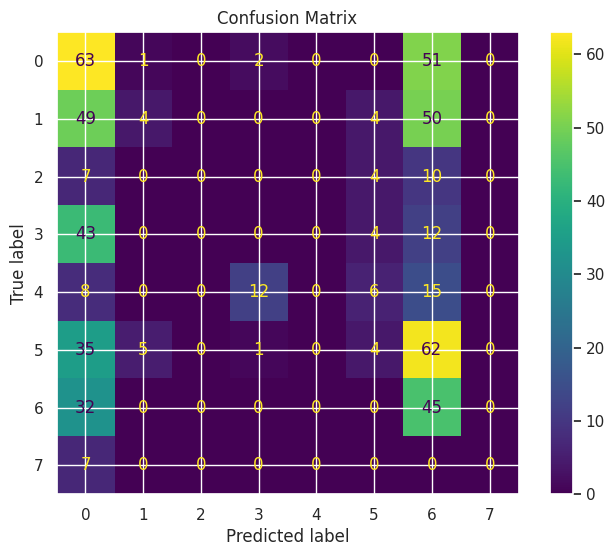

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_3
------------------------------
TRAIN
Accuracy: 0.8679
Precision: 0.8655
Recall: 0.8679
F1: 0.8605
Kappa: 0.8397
Error Rate: 0.1321

TEST
Accuracy: 0.2239
Precision: 0.1291
Recall: 0.2239
F1: 0.1490
Kappa: 0.0568
Error Rate: 0.7761
Gap (overfitting): 0.6440

CV
Mean: 0.8756
Std: 0.0665
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



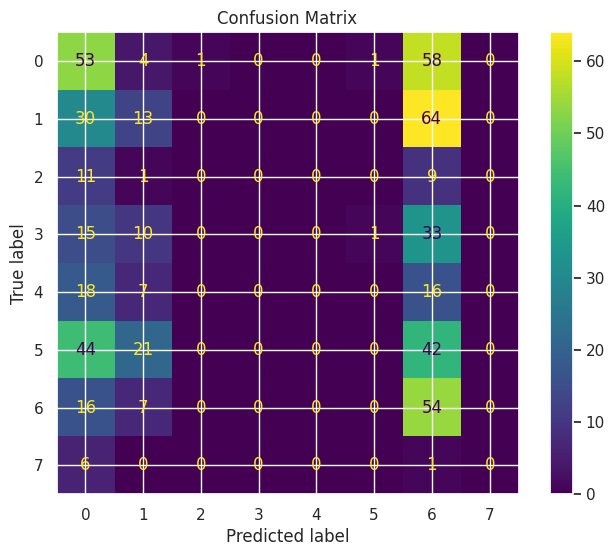

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_4
------------------------------
TRAIN
Accuracy: 0.4676
Precision: 0.4621
Recall: 0.4676
F1: 0.4459
Kappa: 0.3464
Error Rate: 0.5324

TEST
Accuracy: 0.2015
Precision: 0.1328
Recall: 0.2015
F1: 0.0850
Kappa: 0.0017
Error Rate: 0.7985
Gap (overfitting): 0.2661

CV
Mean: 0.5020
Std: 0.0300
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.3, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



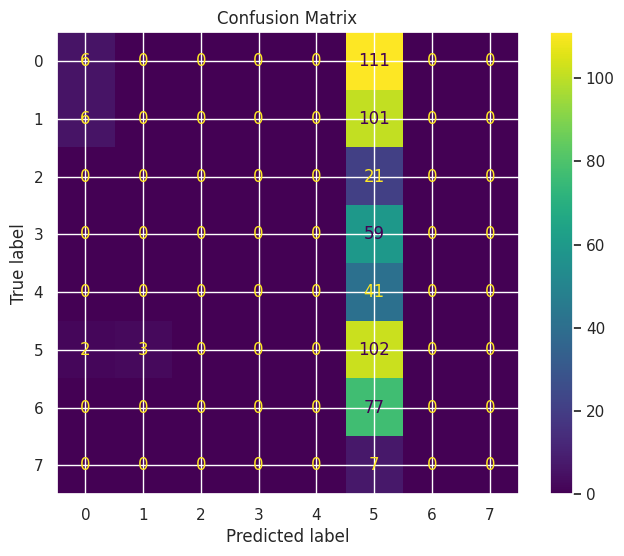

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_5
------------------------------
TRAIN
Accuracy: 0.4171
Precision: 0.4463
Recall: 0.4171
F1: 0.3966
Kappa: 0.2840
Error Rate: 0.5829

TEST
Accuracy: 0.1754
Precision: 0.0658
Recall: 0.1754
F1: 0.0829
Kappa: -0.0039
Error Rate: 0.8246
Gap (overfitting): 0.2418

CV
Mean: 0.4073
Std: 0.0297
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.5, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.5, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



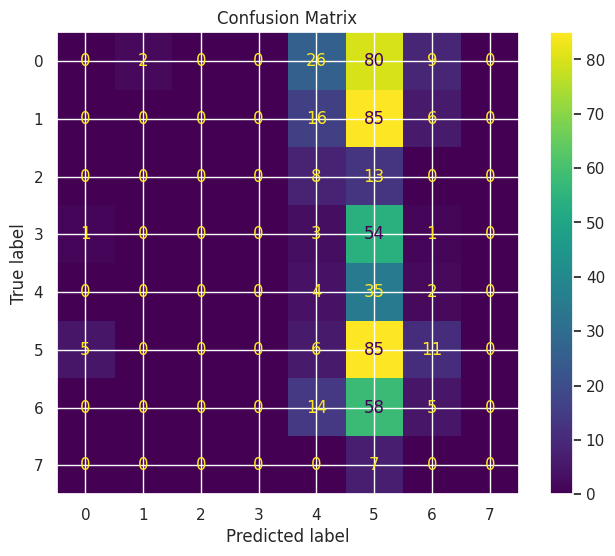

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_6
------------------------------
TRAIN
Accuracy: 0.9992
Precision: 0.9992
Recall: 0.9992
F1: 0.9992
Kappa: 0.9990
Error Rate: 0.0008

TEST
Accuracy: 0.1437
Precision: 0.0212
Recall: 0.1437
F1: 0.0369
Kappa: 0.0037
Error Rate: 0.8563
Gap (overfitting): 0.8555

CV
Mean: 0.9322
Std: 0.0509
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



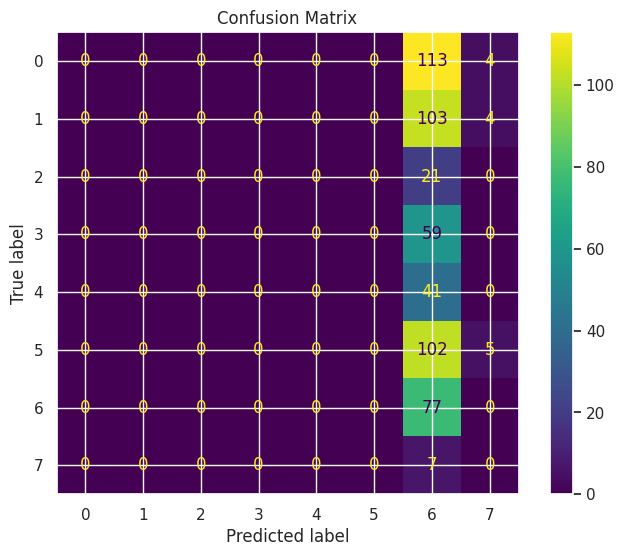

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_7
------------------------------
TRAIN
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1: 1.0000
Kappa: 1.0000
Error Rate: 0.0000

TEST
Accuracy: 0.0578
Precision: 0.0689
Recall: 0.0578
F1: 0.0152
Kappa: -0.0258
Error Rate: 0.9422
Gap (overfitting): 0.9422

CV
Mean: 0.9647
Std: 0.0367
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



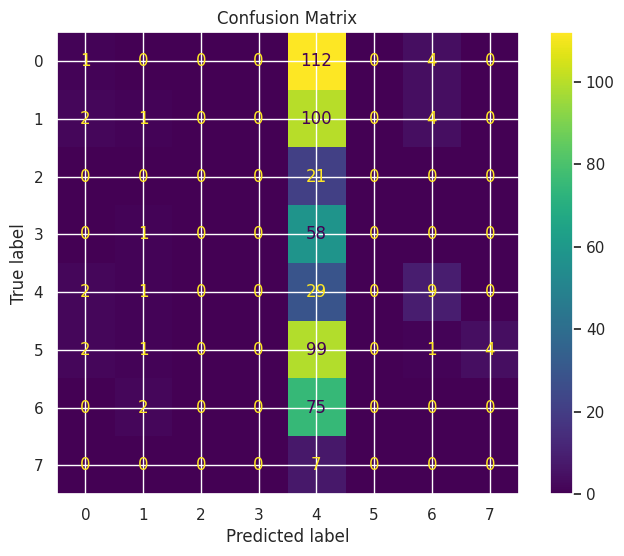

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_8
------------------------------
TRAIN
Accuracy: 0.9888
Precision: 0.9892
Recall: 0.9888
F1: 0.9888
Kappa: 0.9865
Error Rate: 0.0112

TEST
Accuracy: 0.2015
Precision: 0.1063
Recall: 0.2015
F1: 0.0764
Kappa: 0.0023
Error Rate: 0.7985
Gap (overfitting): 0.7873

CV
Mean: 0.9440
Std: 0.0349
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



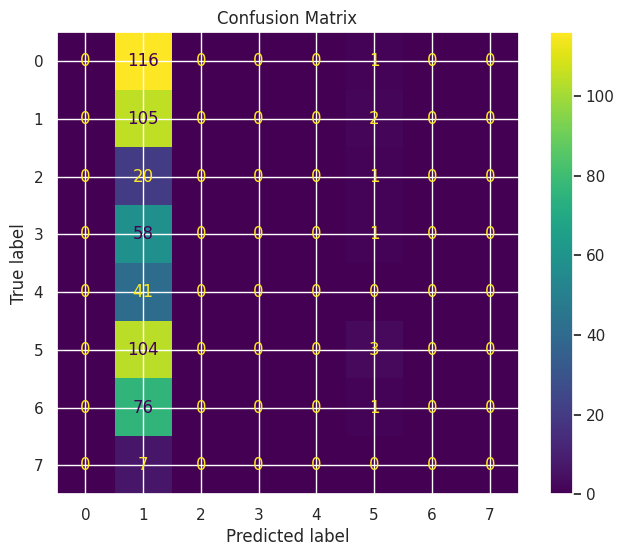

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_9
------------------------------
TRAIN
Accuracy: 0.5340
Precision: 0.5107
Recall: 0.5340
F1: 0.5139
Kappa: 0.4305
Error Rate: 0.4660

TEST
Accuracy: 0.2220
Precision: 0.1071
Recall: 0.2220
F1: 0.1240
Kappa: 0.0797
Error Rate: 0.7780
Gap (overfitting): 0.3120

CV
Mean: 0.6303
Std: 0.0431
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



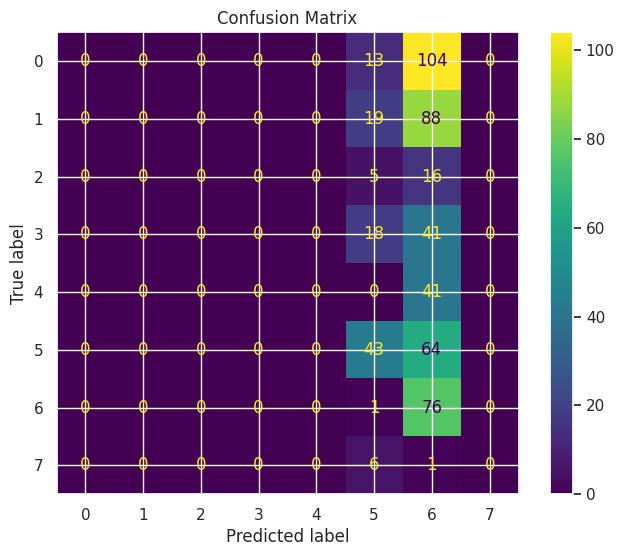

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_10
------------------------------
TRAIN
Accuracy: 0.7678
Precision: 0.7764
Recall: 0.7678
F1: 0.7598
Kappa: 0.7174
Error Rate: 0.2322

TEST
Accuracy: 0.0821
Precision: 0.0427
Recall: 0.0821
F1: 0.0409
Kappa: -0.0207
Error Rate: 0.9179
Gap (overfitting): 0.6857

CV
Mean: 0.8342
Std: 0.0594
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



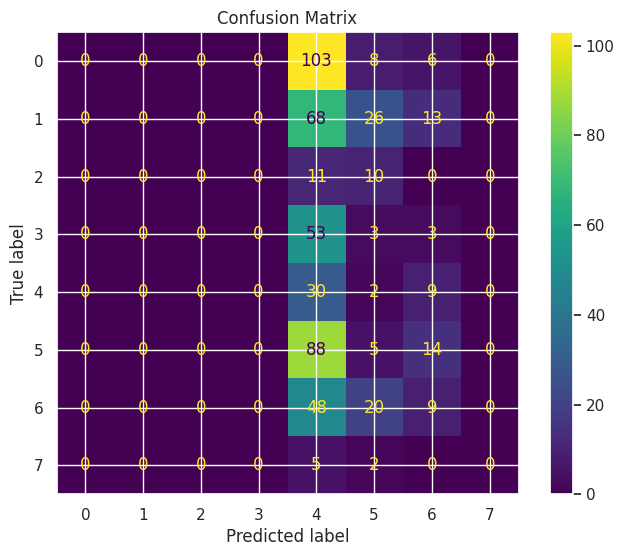

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_11
------------------------------
TRAIN
Accuracy: 0.7606
Precision: 0.7813
Recall: 0.7606
F1: 0.7592
Kappa: 0.7097
Error Rate: 0.2394

TEST
Accuracy: 0.2351
Precision: 0.1579
Recall: 0.2351
F1: 0.1683
Kappa: 0.0605
Error Rate: 0.7649
Gap (overfitting): 0.5255

CV
Mean: 0.7882
Std: 0.0522
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



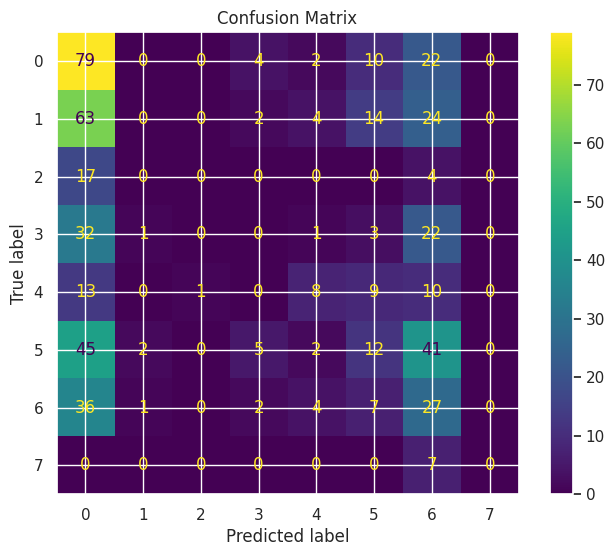

In [7]:
models_cnn_gru_f1 = {}


# ============================================================
# 1º MELHOR: CNN_GRU_sgd_momentum
# ============================================================


models_cnn_gru_f1['CNN_1'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_2'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas CNN + 2 camadas GRU
models_cnn_gru_f1['CNN_3'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_cnn_gru_f1['CNN_4'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.3,
    gru_hidden=50, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_5'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.5,
    gru_hidden=50, gru_layers=1, gru_dropout=0.5, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: CNN_GRU_rmsprop
# ============================================================


models_cnn_gru_f1['CNN_6'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_7'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_8'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: CNN_GRU_adam_lowLR
# ============================================================


models_cnn_gru_f1['CNN_9'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_10'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f1['CNN_11'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_cnn_gru_f1, "cnn_gru_fase_1")

/tmp/ipykernel_606/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_12
------------------------------
TRAIN
Accuracy: 0.6237
Precision: 0.6532
Recall: 0.6237
F1: 0.6085
Kappa: 0.5384
Error Rate: 0.3763

TEST
Accuracy: 0.1437
Precision: 0.1036
Recall: 0.1437
F1: 0.0936
Kappa: 0.0267
Error Rate: 0.8563
Gap (overfitting): 0.4800

CV
Mean: 0.6616
Std: 0.0741
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



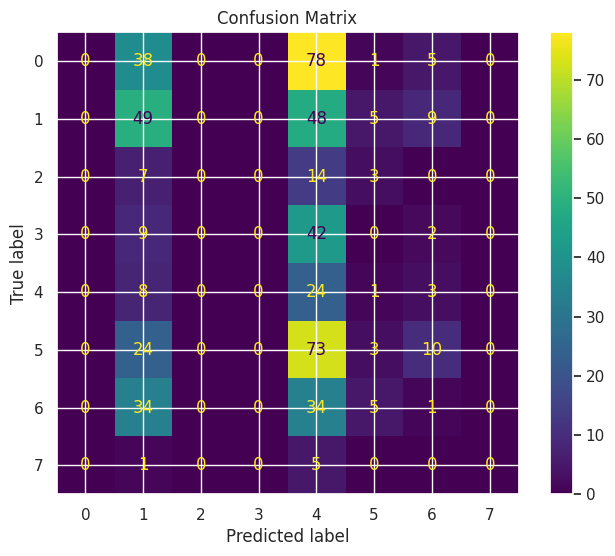

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_13
------------------------------
TRAIN
Accuracy: 0.7462
Precision: 0.7693
Recall: 0.7462
F1: 0.7386
Kappa: 0.6882
Error Rate: 0.2538

TEST
Accuracy: 0.1549
Precision: 0.1816
Recall: 0.1549
F1: 0.0921
Kappa: 0.0412
Error Rate: 0.8451
Gap (overfitting): 0.5913

CV
Mean: 0.7714
Std: 0.0958
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



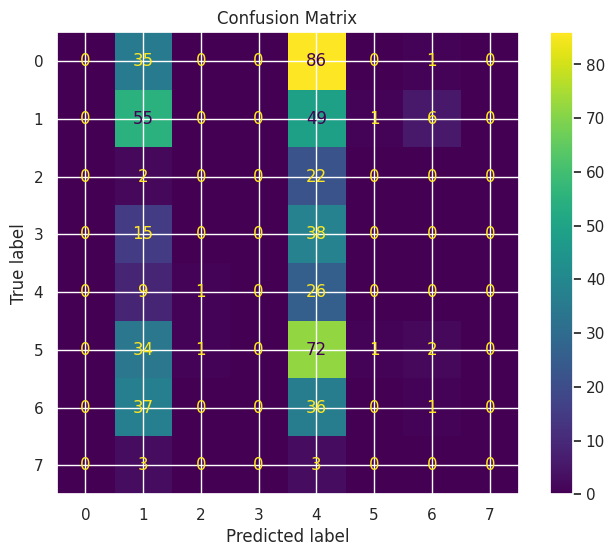

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_14
------------------------------
TRAIN
Accuracy: 0.9968
Precision: 0.9968
Recall: 0.9968
F1: 0.9968
Kappa: 0.9961
Error Rate: 0.0032

TEST
Accuracy: 0.1828
Precision: 0.1750
Recall: 0.1828
F1: 0.1560
Kappa: 0.0167
Error Rate: 0.8172
Gap (overfitting): 0.8140

CV
Mean: 0.8493
Std: 0.1121
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



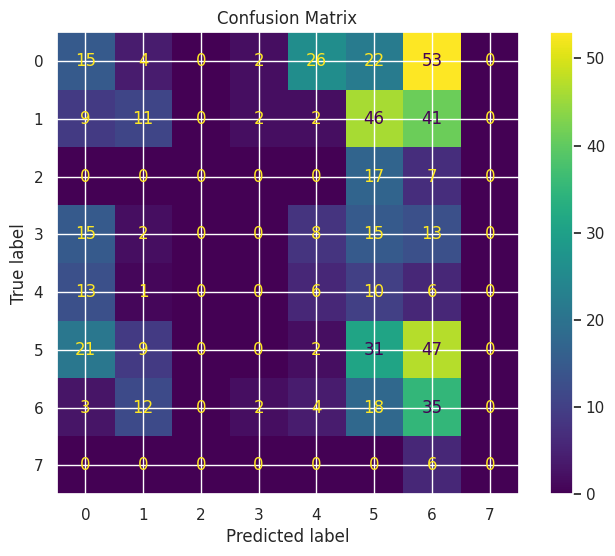

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_15
------------------------------
TRAIN
Accuracy: 0.4796
Precision: 0.4090
Recall: 0.4796
F1: 0.4262
Kappa: 0.3484
Error Rate: 0.5204

TEST
Accuracy: 0.1418
Precision: 0.1201
Recall: 0.1418
F1: 0.1203
Kappa: -0.0486
Error Rate: 0.8582
Gap (overfitting): 0.3378

CV
Mean: 0.4616
Std: 0.0378
------------------------------
Model params:
{'cnn_filters': [10], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 10, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



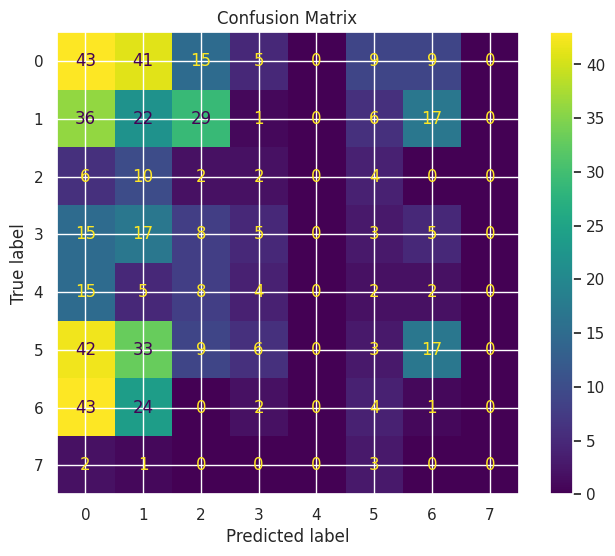

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_16
------------------------------
TRAIN
Accuracy: 0.6237
Precision: 0.6532
Recall: 0.6237
F1: 0.6085
Kappa: 0.5384
Error Rate: 0.3763

TEST
Accuracy: 0.1437
Precision: 0.1036
Recall: 0.1437
F1: 0.0936
Kappa: 0.0267
Error Rate: 0.8563
Gap (overfitting): 0.4800

CV
Mean: 0.6616
Std: 0.0741
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



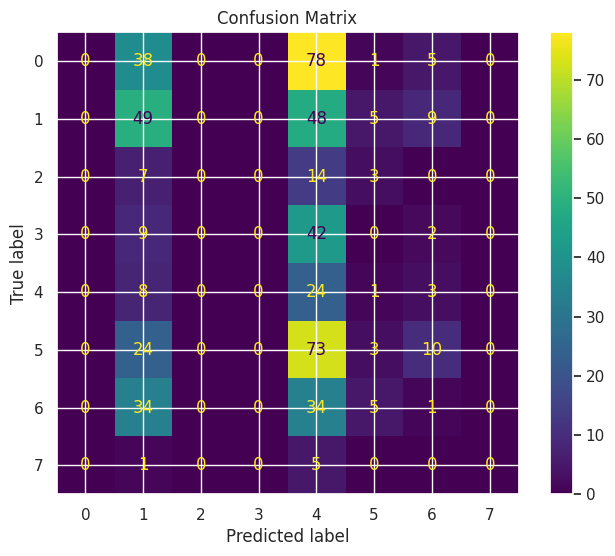

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_17
------------------------------
TRAIN
Accuracy: 0.7622
Precision: 0.7684
Recall: 0.7622
F1: 0.7594
Kappa: 0.7100
Error Rate: 0.2378

TEST
Accuracy: 0.1978
Precision: 0.1084
Recall: 0.1978
F1: 0.1057
Kappa: 0.0144
Error Rate: 0.8022
Gap (overfitting): 0.5644

CV
Mean: 0.8106
Std: 0.0904
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



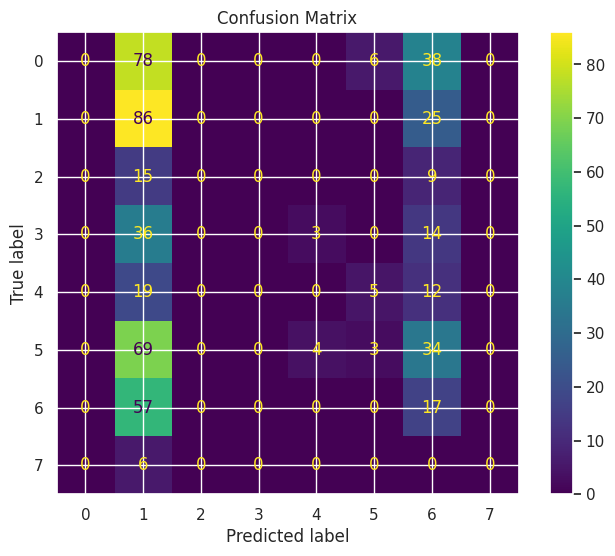

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_18
------------------------------
TRAIN
Accuracy: 0.7110
Precision: 0.7154
Recall: 0.7110
F1: 0.6887
Kappa: 0.6424
Error Rate: 0.2890

TEST
Accuracy: 0.1884
Precision: 0.1207
Recall: 0.1884
F1: 0.1356
Kappa: 0.0024
Error Rate: 0.8116
Gap (overfitting): 0.5225

CV
Mean: 0.7109
Std: 0.1251
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



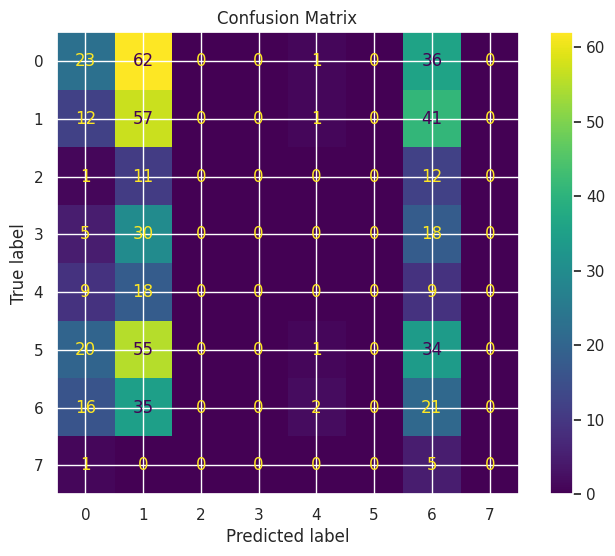

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_19
------------------------------
TRAIN
Accuracy: 0.6237
Precision: 0.6532
Recall: 0.6237
F1: 0.6085
Kappa: 0.5384
Error Rate: 0.3763

TEST
Accuracy: 0.1437
Precision: 0.1036
Recall: 0.1437
F1: 0.0936
Kappa: 0.0267
Error Rate: 0.8563
Gap (overfitting): 0.4800

CV
Mean: 0.6616
Std: 0.0741
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



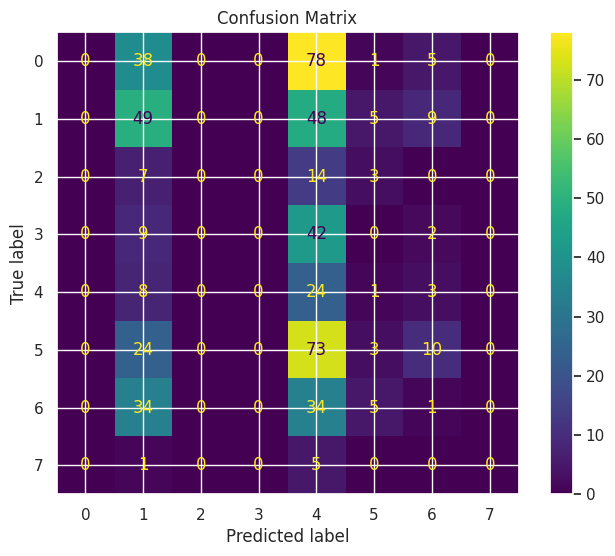

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_20
------------------------------
TRAIN
Accuracy: 0.5132
Precision: 0.5617
Recall: 0.5132
F1: 0.5014
Kappa: 0.4005
Error Rate: 0.4868

TEST
Accuracy: 0.2183
Precision: 0.1505
Recall: 0.2183
F1: 0.1695
Kappa: 0.0647
Error Rate: 0.7817
Gap (overfitting): 0.2949

CV
Mean: 0.6084
Std: 0.0388
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.1, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



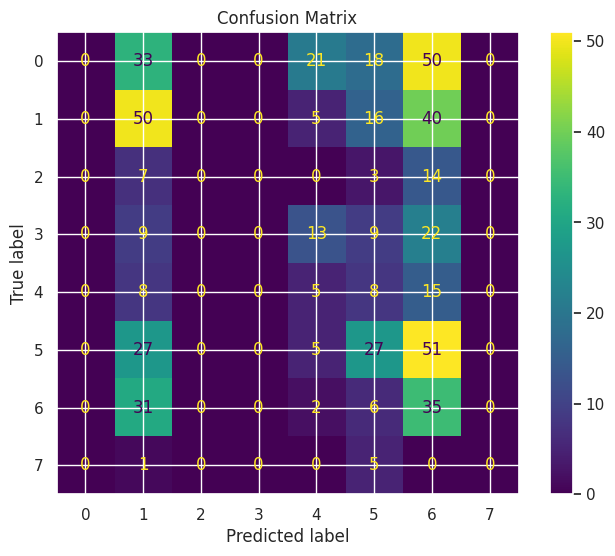

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_21
------------------------------
TRAIN
Accuracy: 0.4724
Precision: 0.5260
Recall: 0.4724
F1: 0.4503
Kappa: 0.3503
Error Rate: 0.5276

TEST
Accuracy: 0.1791
Precision: 0.1386
Recall: 0.1791
F1: 0.1315
Kappa: 0.0092
Error Rate: 0.8209
Gap (overfitting): 0.2933

CV
Mean: 0.5171
Std: 0.0335
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



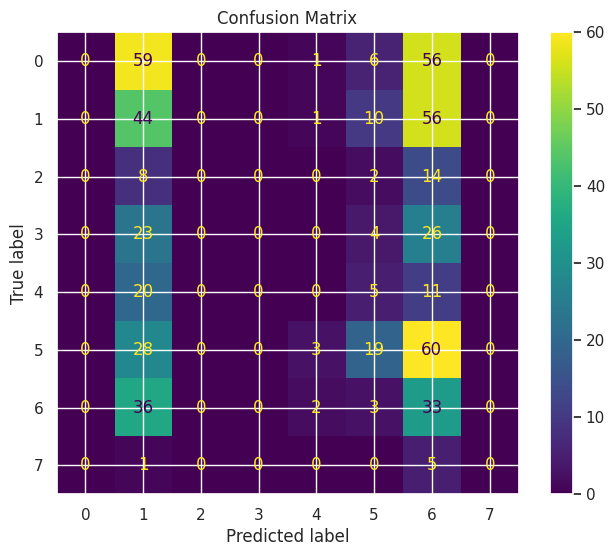

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_22
------------------------------
TRAIN
Accuracy: 0.4371
Precision: 0.3868
Recall: 0.4371
F1: 0.4037
Kappa: 0.3055
Error Rate: 0.5629

TEST
Accuracy: 0.2015
Precision: 0.1213
Recall: 0.2015
F1: 0.1237
Kappa: 0.0065
Error Rate: 0.7985
Gap (overfitting): 0.2357

CV
Mean: 0.4465
Std: 0.0336
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.3, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



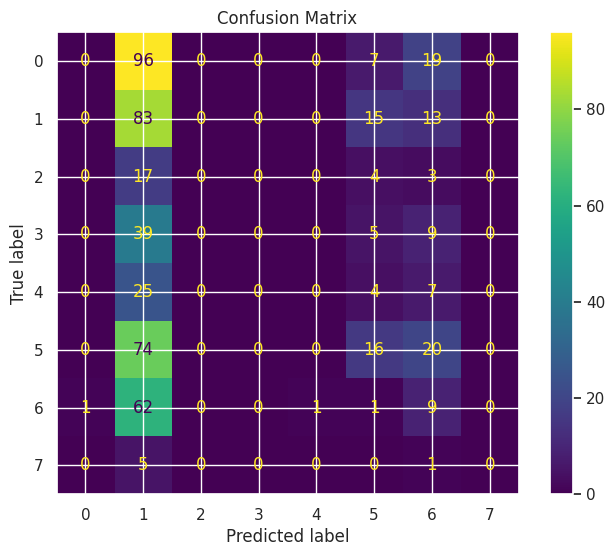

In [8]:
models_cnn_gru_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_cnn_gru_f2['CNN_12'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f2['CNN_13'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f2['CNN_14'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================


# equivalente a hidden=10
models_cnn_gru_f2['CNN_15'] = CNN_GRU_Hybrid(
    cnn_filters=[10], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=10, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=30
models_cnn_gru_f2['CNN_16'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50
models_cnn_gru_f2['CNN_17'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas CNN + 2 camadas GRU (50_25)
models_cnn_gru_f2['CNN_18'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_cnn_gru_f2['CNN_19'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f2['CNN_20'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.1,
    gru_hidden=30, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f2['CNN_21'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f2['CNN_22'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.3,
    gru_hidden=30, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_cnn_gru_f2, "cnn_gru_fase_2")

/tmp/ipykernel_606/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_23
------------------------------
TRAIN
Accuracy: 0.7526
Precision: 0.7501
Recall: 0.7526
F1: 0.7447
Kappa: 0.6984
Error Rate: 0.2474

TEST
Accuracy: 0.1213
Precision: 0.1312
Recall: 0.1213
F1: 0.1175
Kappa: -0.0353
Error Rate: 0.8787
Gap (overfitting): 0.6313

CV
Mean: 0.7429
Std: 0.1001
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



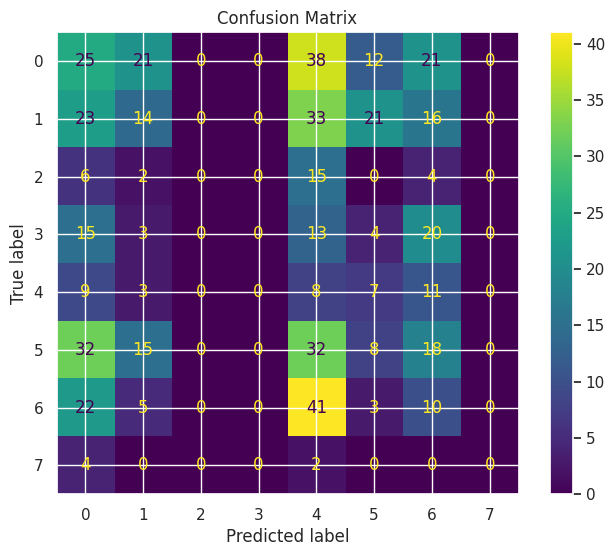

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_24
------------------------------
TRAIN
Accuracy: 0.9440
Precision: 0.9460
Recall: 0.9440
F1: 0.9435
Kappa: 0.9323
Error Rate: 0.0560

TEST
Accuracy: 0.2015
Precision: 0.2161
Recall: 0.2015
F1: 0.1666
Kappa: 0.0421
Error Rate: 0.7985
Gap (overfitting): 0.7425

CV
Mean: 0.8493
Std: 0.1195
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



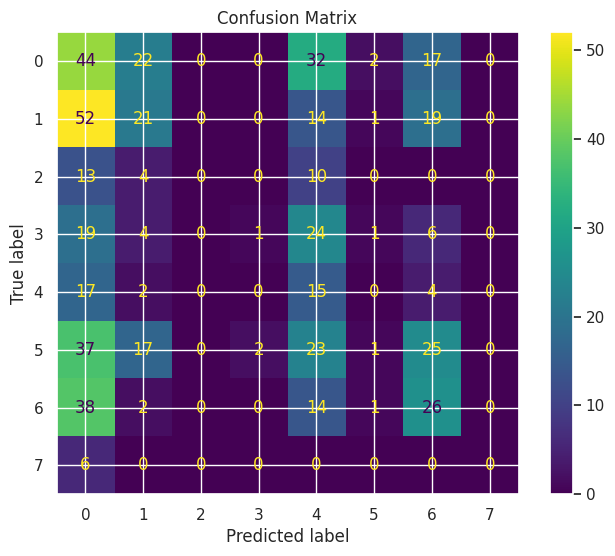

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_25
------------------------------
TRAIN
Accuracy: 0.8575
Precision: 0.8676
Recall: 0.8575
F1: 0.8570
Kappa: 0.8274
Error Rate: 0.1425

TEST
Accuracy: 0.1810
Precision: 0.1652
Recall: 0.1810
F1: 0.1313
Kappa: 0.0214
Error Rate: 0.8190
Gap (overfitting): 0.6765

CV
Mean: 0.8241
Std: 0.0960
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



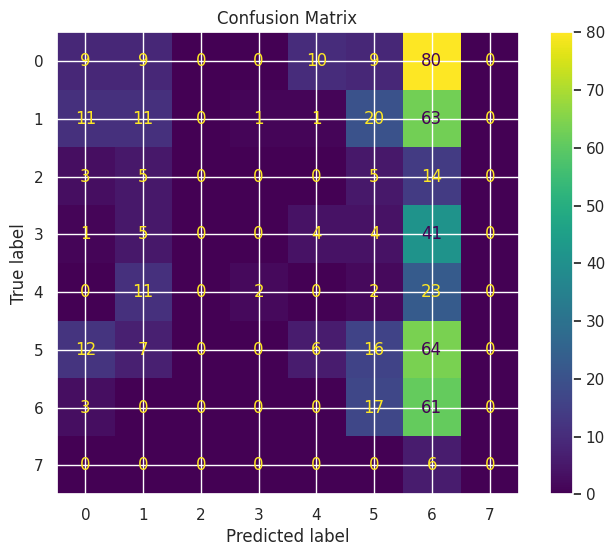

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_26
------------------------------
TRAIN
Accuracy: 0.9712
Precision: 0.9728
Recall: 0.9712
F1: 0.9709
Kappa: 0.9652
Error Rate: 0.0288

TEST
Accuracy: 0.1698
Precision: 0.1454
Recall: 0.1698
F1: 0.1019
Kappa: 0.0150
Error Rate: 0.8302
Gap (overfitting): 0.8014

CV
Mean: 0.8829
Std: 0.0995
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



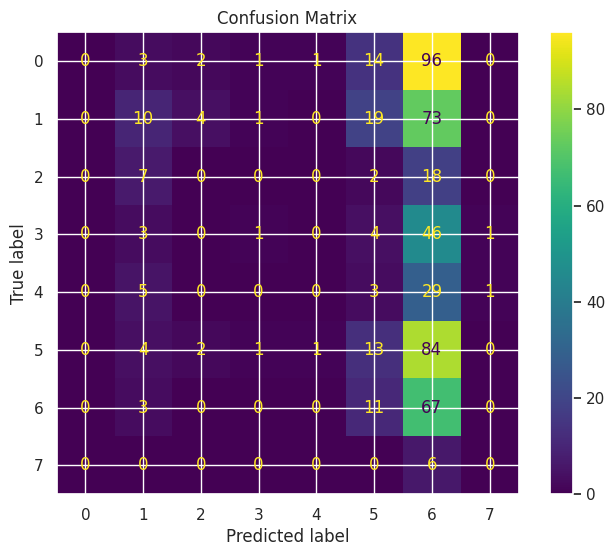

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_27
------------------------------
TRAIN
Accuracy: 0.8070
Precision: 0.8268
Recall: 0.8070
F1: 0.8034
Kappa: 0.7647
Error Rate: 0.1930

TEST
Accuracy: 0.1623
Precision: 0.1420
Recall: 0.1623
F1: 0.0962
Kappa: -0.0217
Error Rate: 0.8377
Gap (overfitting): 0.6447

CV
Mean: 0.8616
Std: 0.0968
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



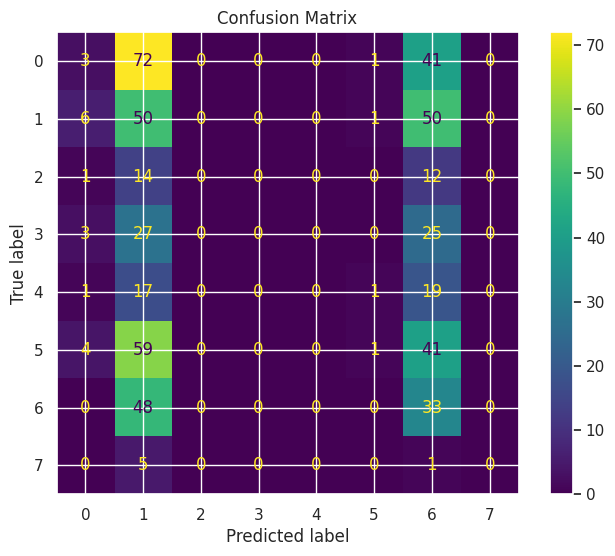


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_28
------------------------------
TRAIN
Accuracy: 0.9648
Precision: 0.9659
Recall: 0.9648
F1: 0.9650
Kappa: 0.9576
Error Rate: 0.0352

TEST
Accuracy: 0.1698
Precision: 0.1588
Recall: 0.1698
F1: 0.1022
Kappa: -0.0208
Error Rate: 0.8302
Gap (overfitting): 0.7950

CV
Mean: 0.8896
Std: 0.1018
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



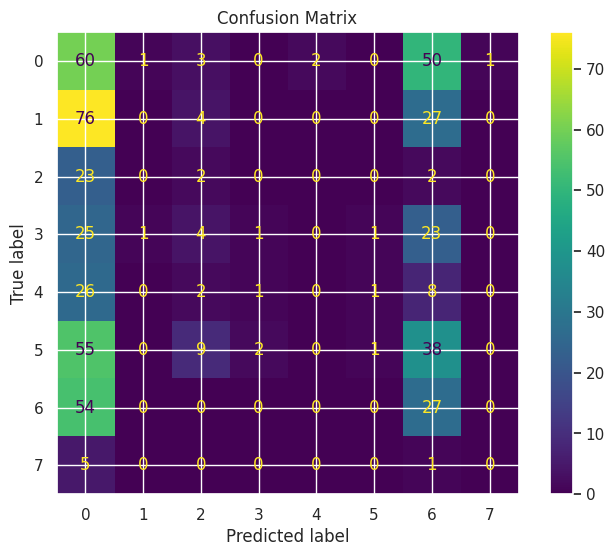

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_29
------------------------------
TRAIN
Accuracy: 0.4412
Precision: 0.3880
Recall: 0.4412
F1: 0.4100
Kappa: 0.3143
Error Rate: 0.5588

TEST
Accuracy: 0.1884
Precision: 0.1660
Recall: 0.1884
F1: 0.0941
Kappa: 0.0365
Error Rate: 0.8116
Gap (overfitting): 0.2527

CV
Mean: 0.4807
Std: 0.0130
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



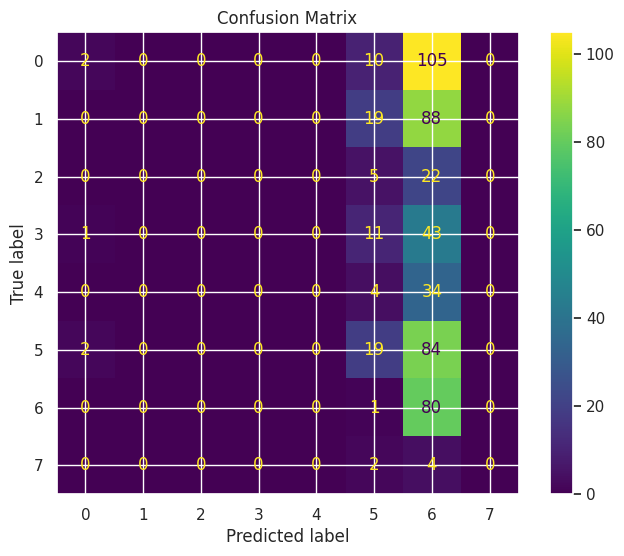

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30
------------------------------
TRAIN
Accuracy: 0.5981
Precision: 0.6484
Recall: 0.5981
F1: 0.5879
Kappa: 0.5061
Error Rate: 0.4019

TEST
Accuracy: 0.1810
Precision: 0.0556
Recall: 0.1810
F1: 0.0833
Kappa: -0.0043
Error Rate: 0.8190
Gap (overfitting): 0.4171

CV
Mean: 0.6644
Std: 0.0531
------------------------------
Model params:
{'cnn_filters': [16], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 50, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



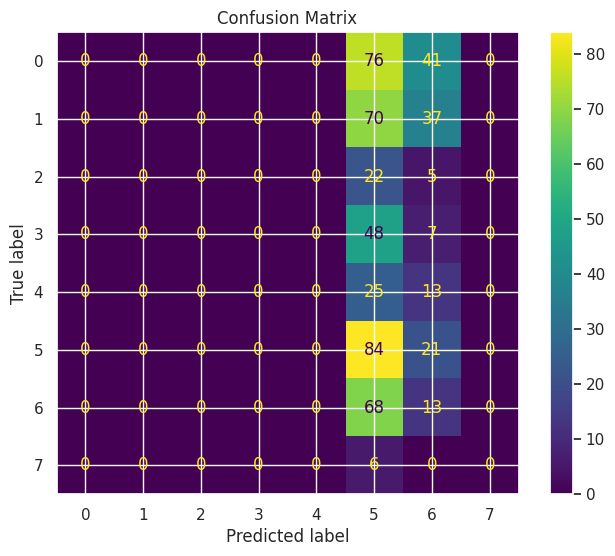

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_31
------------------------------
TRAIN
Accuracy: 0.4580
Precision: 0.4232
Recall: 0.4580
F1: 0.4199
Kappa: 0.3331
Error Rate: 0.5420

TEST
Accuracy: 0.2164
Precision: 0.0943
Recall: 0.2164
F1: 0.1172
Kappa: 0.0024
Error Rate: 0.7836
Gap (overfitting): 0.2415

CV
Mean: 0.4588
Std: 0.0166
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.2, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



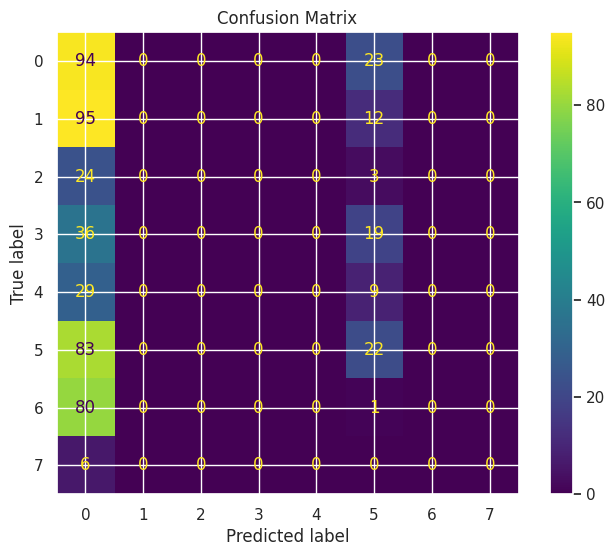

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_32
------------------------------
TRAIN
Accuracy: 0.4940
Precision: 0.4960
Recall: 0.4940
F1: 0.4707
Kappa: 0.3795
Error Rate: 0.5060

TEST
Accuracy: 0.1474
Precision: 0.1463
Recall: 0.1474
F1: 0.1059
Kappa: -0.0464
Error Rate: 0.8526
Gap (overfitting): 0.3466

CV
Mean: 0.4852
Std: 0.0200
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



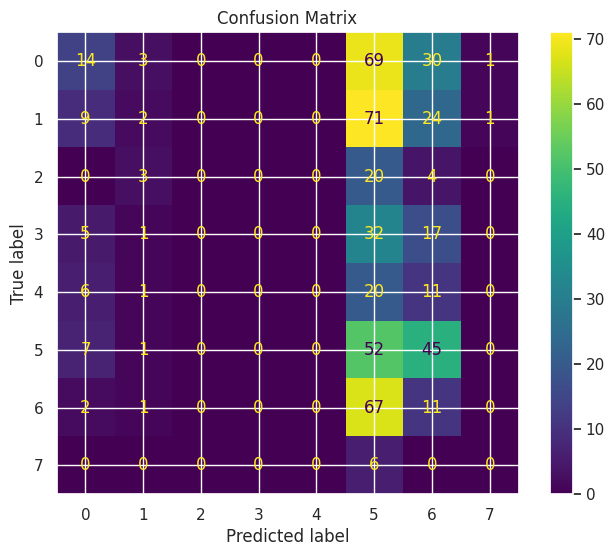

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_33
------------------------------
TRAIN
Accuracy: 0.4163
Precision: 0.3723
Recall: 0.4163
F1: 0.3883
Kappa: 0.2851
Error Rate: 0.5837

TEST
Accuracy: 0.2071
Precision: 0.2038
Recall: 0.2071
F1: 0.1336
Kappa: 0.0521
Error Rate: 0.7929
Gap (overfitting): 0.2092

CV
Mean: 0.4392
Std: 0.0156
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.3, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



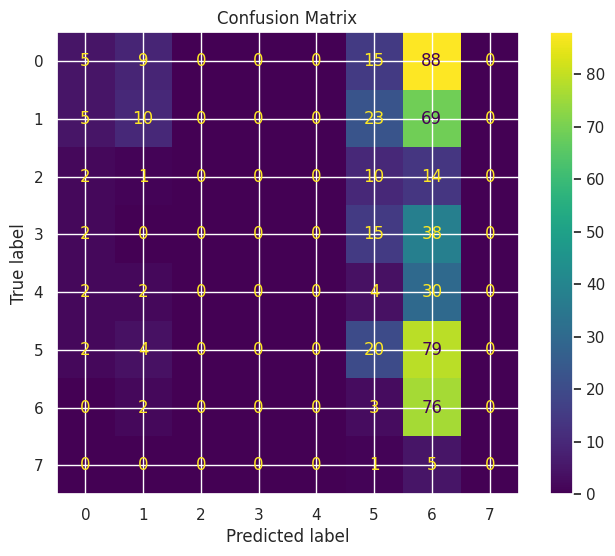

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_34
------------------------------
TRAIN
Accuracy: 0.3106
Precision: 0.2657
Recall: 0.3106
F1: 0.2382
Kappa: 0.1249
Error Rate: 0.6894

TEST
Accuracy: 0.2052
Precision: 0.2075
Recall: 0.2052
F1: 0.1302
Kappa: 0.0534
Error Rate: 0.7948
Gap (overfitting): 0.1054

CV
Mean: 0.3188
Std: 0.0162
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



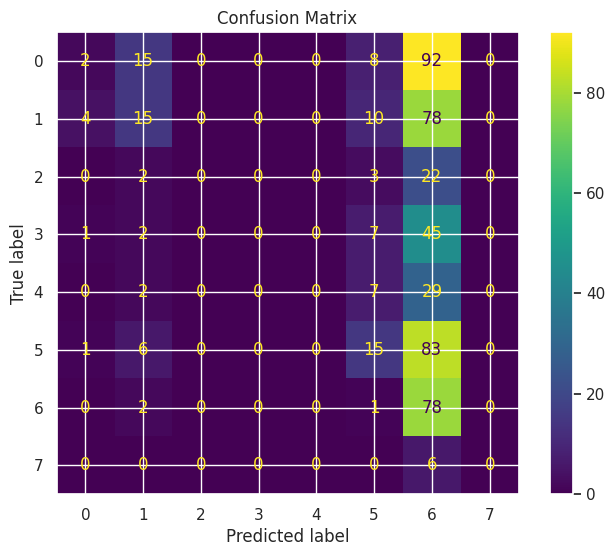

In [9]:
models_cnn_gru_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_cnn_gru_f3['F2_23'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_24'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_25'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_26'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=50, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_27'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_28'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_cnn_gru_f3['F2_29'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_30'] = CNN_GRU_Hybrid(
    cnn_filters=[16], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=50, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_31'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.2,
    gru_hidden=25, gru_layers=2, gru_dropout=0.2, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_cnn_gru_f3['F2_32'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_33'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.3,
    gru_hidden=30, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f3['F2_34'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_cnn_gru_f3, "cnn_gru_fase_3")

/tmp/ipykernel_606/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_31
------------------------------
TRAIN
Accuracy: 0.6245
Precision: 0.6515
Recall: 0.6245
F1: 0.6126
Kappa: 0.5427
Error Rate: 0.3755

TEST
Accuracy: 0.1847
Precision: 0.1815
Recall: 0.1847
F1: 0.0988
Kappa: 0.0108
Error Rate: 0.8153
Gap (overfitting): 0.4398

CV
Mean: 0.5972
Std: 0.1048
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



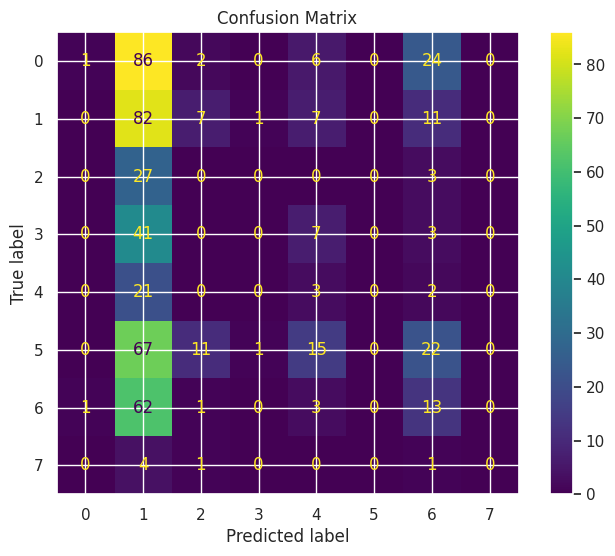

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_32
------------------------------
TRAIN
Accuracy: 0.4748
Precision: 0.4696
Recall: 0.4748
F1: 0.4574
Kappa: 0.3563
Error Rate: 0.5252

TEST
Accuracy: 0.2015
Precision: 0.2265
Recall: 0.2015
F1: 0.1034
Kappa: 0.0224
Error Rate: 0.7985
Gap (overfitting): 0.2733

CV
Mean: 0.4717
Std: 0.0369
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



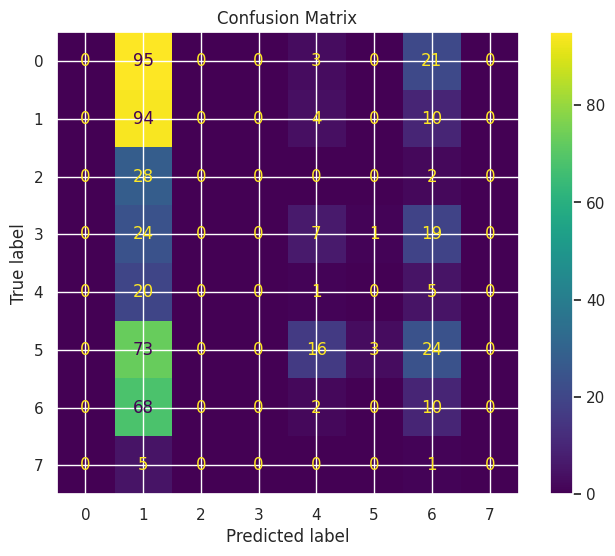

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_33
------------------------------
TRAIN
Accuracy: 0.3187
Precision: 0.2139
Recall: 0.3187
F1: 0.2501
Kappa: 0.1404
Error Rate: 0.6813

TEST
Accuracy: 0.2201
Precision: 0.3873
Recall: 0.2201
F1: 0.1634
Kappa: 0.0683
Error Rate: 0.7799
Gap (overfitting): 0.0985

CV
Mean: 0.3193
Std: 0.0106
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.0, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



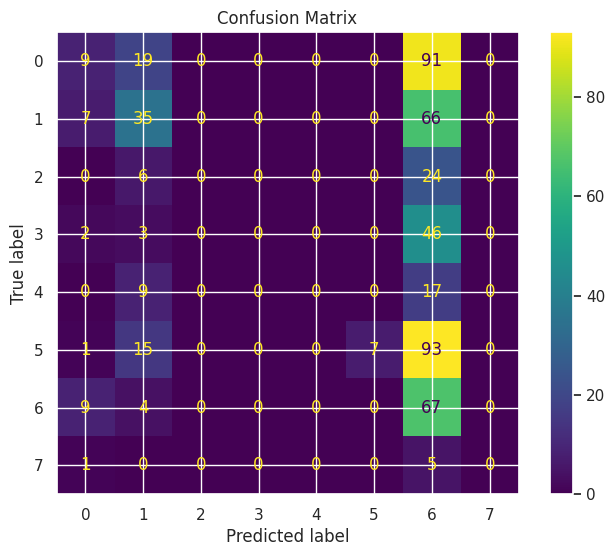

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_34
------------------------------
TRAIN
Accuracy: 0.5116
Precision: 0.5061
Recall: 0.5116
F1: 0.4935
Kappa: 0.4035
Error Rate: 0.4884

TEST
Accuracy: 0.2015
Precision: 0.2055
Recall: 0.2015
F1: 0.1352
Kappa: 0.0472
Error Rate: 0.7985
Gap (overfitting): 0.3101

CV
Mean: 0.5277
Std: 0.0408
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.1, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



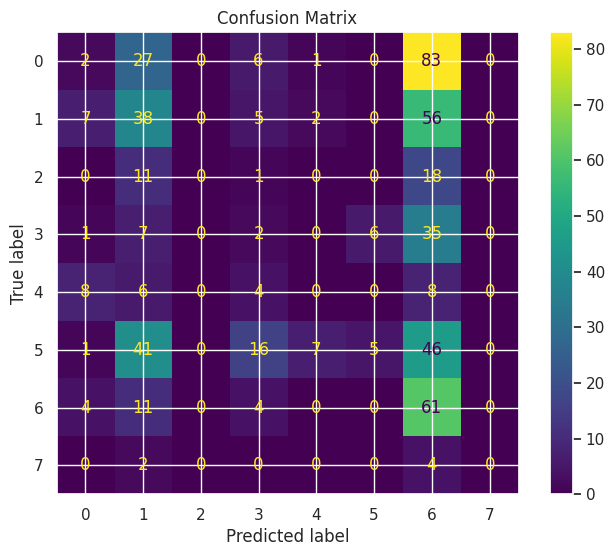

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_35
------------------------------
TRAIN
Accuracy: 0.4604
Precision: 0.4571
Recall: 0.4604
F1: 0.4456
Kappa: 0.3389
Error Rate: 0.5396

TEST
Accuracy: 0.1866
Precision: 0.2505
Recall: 0.1866
F1: 0.1174
Kappa: 0.0455
Error Rate: 0.8134
Gap (overfitting): 0.2738

CV
Mean: 0.4633
Std: 0.0305
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



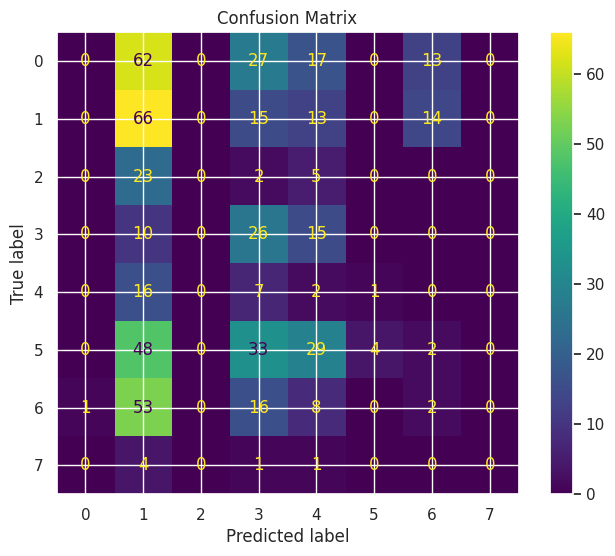

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_36
------------------------------
TRAIN
Accuracy: 0.4235
Precision: 0.4330
Recall: 0.4235
F1: 0.4091
Kappa: 0.2931
Error Rate: 0.5765

TEST
Accuracy: 0.2407
Precision: 0.1257
Recall: 0.2407
F1: 0.1467
Kappa: 0.0521
Error Rate: 0.7593
Gap (overfitting): 0.1829

CV
Mean: 0.4230
Std: 0.0252
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.3, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



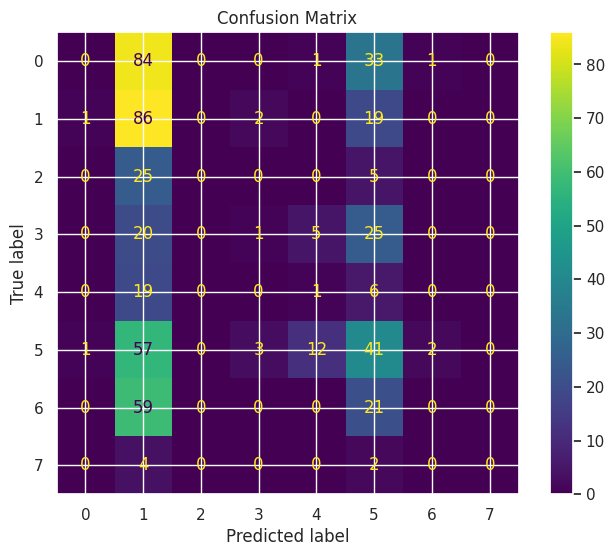

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_37
------------------------------
TRAIN
Accuracy: 0.4099
Precision: 0.4266
Recall: 0.4099
F1: 0.3795
Kappa: 0.2693
Error Rate: 0.5901

TEST
Accuracy: 0.1996
Precision: 0.0728
Recall: 0.1996
F1: 0.1039
Kappa: 0.0354
Error Rate: 0.8004
Gap (overfitting): 0.2103

CV
Mean: 0.4090
Std: 0.0183
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



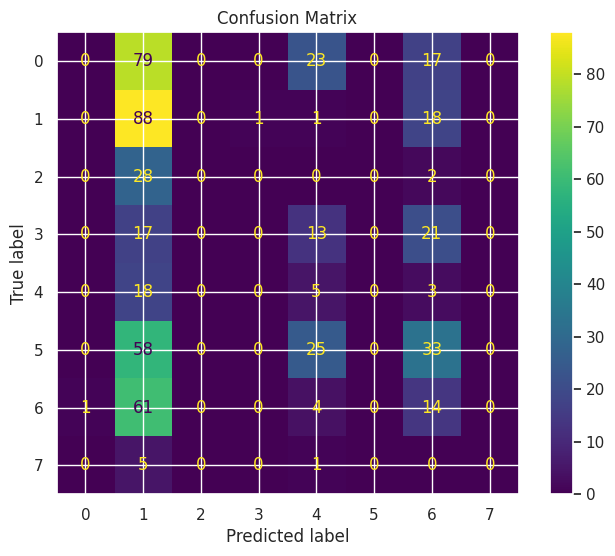

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_38
------------------------------
TRAIN
Accuracy: 0.8175
Precision: 0.8199
Recall: 0.8175
F1: 0.8151
Kappa: 0.7798
Error Rate: 0.1825

TEST
Accuracy: 0.2332
Precision: 0.1602
Recall: 0.2332
F1: 0.1760
Kappa: 0.0286
Error Rate: 0.7668
Gap (overfitting): 0.5842

CV
Mean: 0.6980
Std: 0.1619
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



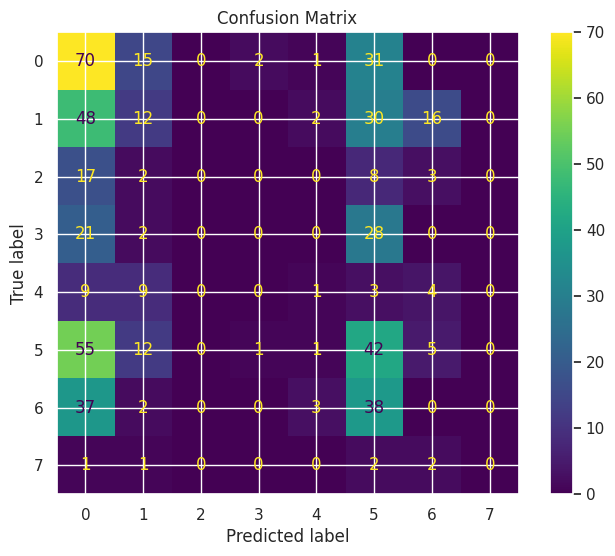

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_39
------------------------------
TRAIN
Accuracy: 0.6117
Precision: 0.5783
Recall: 0.6117
F1: 0.5701
Kappa: 0.5180
Error Rate: 0.3883

TEST
Accuracy: 0.1810
Precision: 0.1500
Recall: 0.1810
F1: 0.1382
Kappa: -0.0113
Error Rate: 0.8190
Gap (overfitting): 0.4307

CV
Mean: 0.6017
Std: 0.1171
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



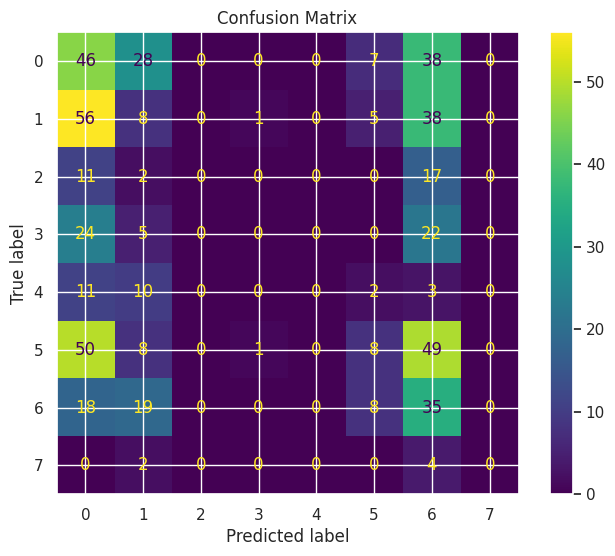

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_40
------------------------------
TRAIN
Accuracy: 0.2666
Precision: 0.1100
Recall: 0.2666
F1: 0.1486
Kappa: 0.0706
Error Rate: 0.7334

TEST
Accuracy: 0.2220
Precision: 0.0493
Recall: 0.2220
F1: 0.0807
Kappa: 0.0000
Error Rate: 0.7780
Gap (overfitting): 0.0446

CV
Mean: 0.2880
Std: 0.0108
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.0, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



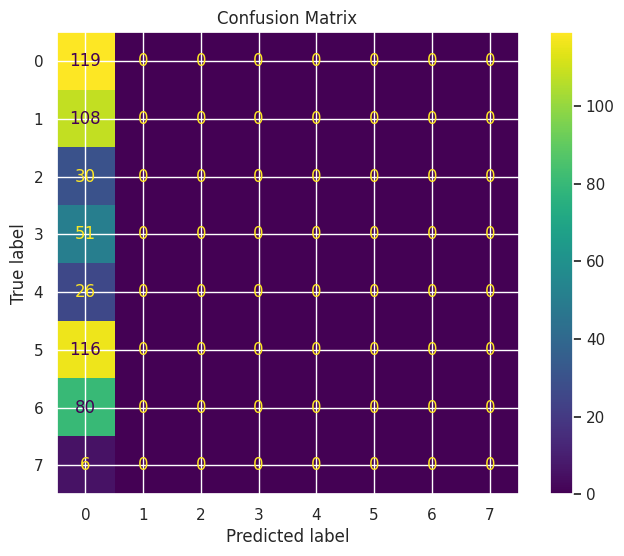

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_41
------------------------------
TRAIN
Accuracy: 0.4299
Precision: 0.3813
Recall: 0.4299
F1: 0.3897
Kappa: 0.2947
Error Rate: 0.5701

TEST
Accuracy: 0.2817
Precision: 0.3142
Recall: 0.2817
F1: 0.1762
Kappa: 0.0817
Error Rate: 0.7183
Gap (overfitting): 0.1482

CV
Mean: 0.4286
Std: 0.0342
------------------------------
Model params:
{'cnn_filters': [16, 8], 'cnn_kernels': [3, 3], 'cnn_dropout': 0.2, 'gru_hidden': 25, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



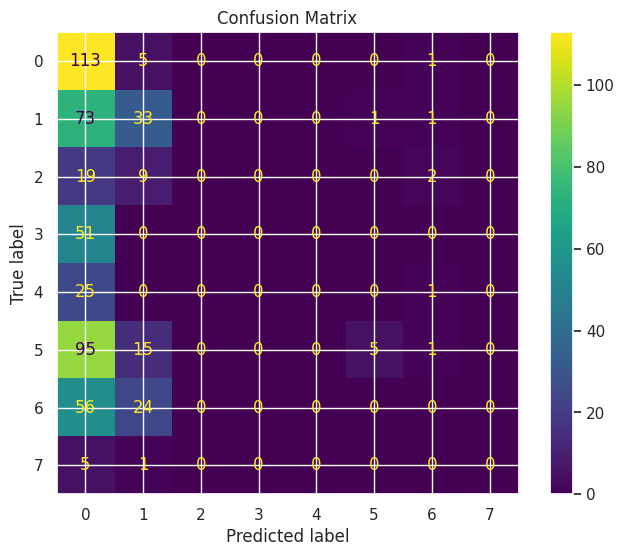

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_42
------------------------------
TRAIN
Accuracy: 0.4131
Precision: 0.4406
Recall: 0.4131
F1: 0.3924
Kappa: 0.2793
Error Rate: 0.5869

TEST
Accuracy: 0.1231
Precision: 0.2836
Recall: 0.1231
F1: 0.0934
Kappa: 0.0340
Error Rate: 0.8769
Gap (overfitting): 0.2900

CV
Mean: 0.4605
Std: 0.0251
------------------------------
Model params:
{'cnn_filters': [8], 'cnn_kernels': [3], 'cnn_dropout': 0.2, 'gru_hidden': 30, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



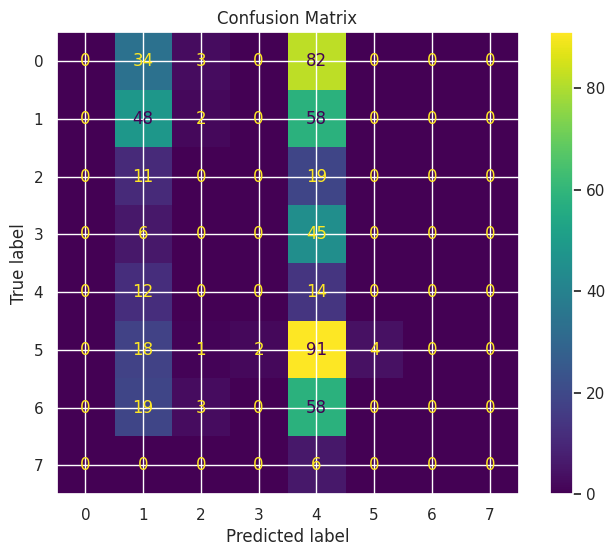

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
models_cnn_gru_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================


models_cnn_gru_f4['F3_31'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_32'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_33'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.0,
    gru_hidden=30, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_34'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.1,
    gru_hidden=30, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_35'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_36'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.3,
    gru_hidden=30, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_37'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com arquitetura 50_25 (2 camadas)
# ============================================================


models_cnn_gru_f4['F3_38'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_39'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_40'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.0,
    gru_hidden=25, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_41'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.2,
    gru_hidden=25, gru_layers=2, gru_dropout=0.2, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================


models_cnn_gru_f4['F3_42'] = CNN_GRU_Hybrid(
    cnn_filters=[8], cnn_kernels=[3], cnn_dropout=0.2,
    gru_hidden=30, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_cnn_gru_f4['F3_43'] = CNN_GRU_Hybrid(
    cnn_filters=[16, 8], cnn_kernels=[3, 3], cnn_dropout=0.2,
    gru_hidden=25, gru_layers=2, gru_dropout=0.2, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_cnn_gru_f4, "cnn_gru_fase_4")